### Gráficas para análisis de influencia del sustituyente 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [2]:
df_fase1 = pd.read_csv('df_final_fase1.csv')
df_fase1

,ID,SMILES_Quiral,MW,LogP,HBD,HBA,TPSA,RotBonds,energia_total_ev,homo_ev,lumo_ev,potencial_quimico_ev,dureza_quimica_ev,electrofilicidad_ev
0,ART,C[C@@H]1CC[C@H]2[C@H](C(=O)O[C@H]3[C@@]24[C@H]...,282.336,2.39490,0,5,53.99,0,-26136.143017,-5.359610,-1.901043,-3.630326,1.729283,3.810616
1,ART-Der-1,C[C@H]1[C@H](OCc2ccc(O)c(O)c2)O[C@@H]2O[C@@]3(...,406.475,3.82240,2,7,86.61,3,-35944.062336,-5.199414,-1.936913,-3.568164,1.631251,3.902464
2,ART-Der-2,C#CCO[C@H]1O[C@@H]2O[C@@]3(C)CC[C@H]4[C@H](C)C...,322.401,2.84420,0,5,46.15,2,-32755.969353,-4.835622,-2.056379,-3.446001,1.389621,4.272718
3,ART-Der-3,CO[C@H]1O[C@@H]2O[C@@]3(C)CC[C@@H]4[C@H](C)CC[...,298.379,2.84080,0,5,46.15,1,-36406.417749,-4.910312,-2.155377,-3.532844,1.377468,4.530412
4,ART-Der-4,C[C@H]1[C@H](OCCCN2CCOCC2)O[C@@H]2O[C@]3(C)CC[...,411.539,2.93330,0,7,58.62,5,-41226.125545,-4.080823,-1.531761,-2.806292,1.274531,3.089479
5,ART-Der-5,CCO[C@@H]1O[C@@H]2O[C@@]3(C)CC[C@H]4[C@H](C)CC...,312.406,3.23090,0,5,46.15,2,-49613.463763,-4.499118,-1.029507,-2.764312,1.734806,2.202386
6,ART-Der-6,C[C@H]1[C@H](OCC(=O)C(F)(F)F)O[C@H]2O[C@]3(C)C...,394.386,3.34240,0,6,63.22,3,-41407.587938,-4.765632,-2.015555,-3.390594,1.375038,4.180293
7,ART-Der-7,Cc1cc(N)cc(CO[C@@H]2O[C@@H]3O[C@@]4(C)CC[C@H]5...,404.507,3.69682,1,7,85.06,3,-29374.617424,-5.097262,-1.835665,-3.466463,1.630799,3.684197
8,ART-Der-8,C=C(CO[C@@H]1O[C@H]2O[C@]3(C)CC[C@@H]4[C@H](C)...,368.470,3.76120,0,6,55.38,5,-51589.533210,-4.871211,-1.832488,-3.351850,1.519362,3.697242
9,ART-Der-9,C[C@@H]1[C@@H](OCc2ccccc2OCC(=O)O)O[C@@H]2O[C@...,448.512,3.87460,1,7,92.68,6,-40344.323899,-4.424727,-1.566808,-2.995768,1.428960,3.140265


### 0) Gráfica de derivados con etiquetas

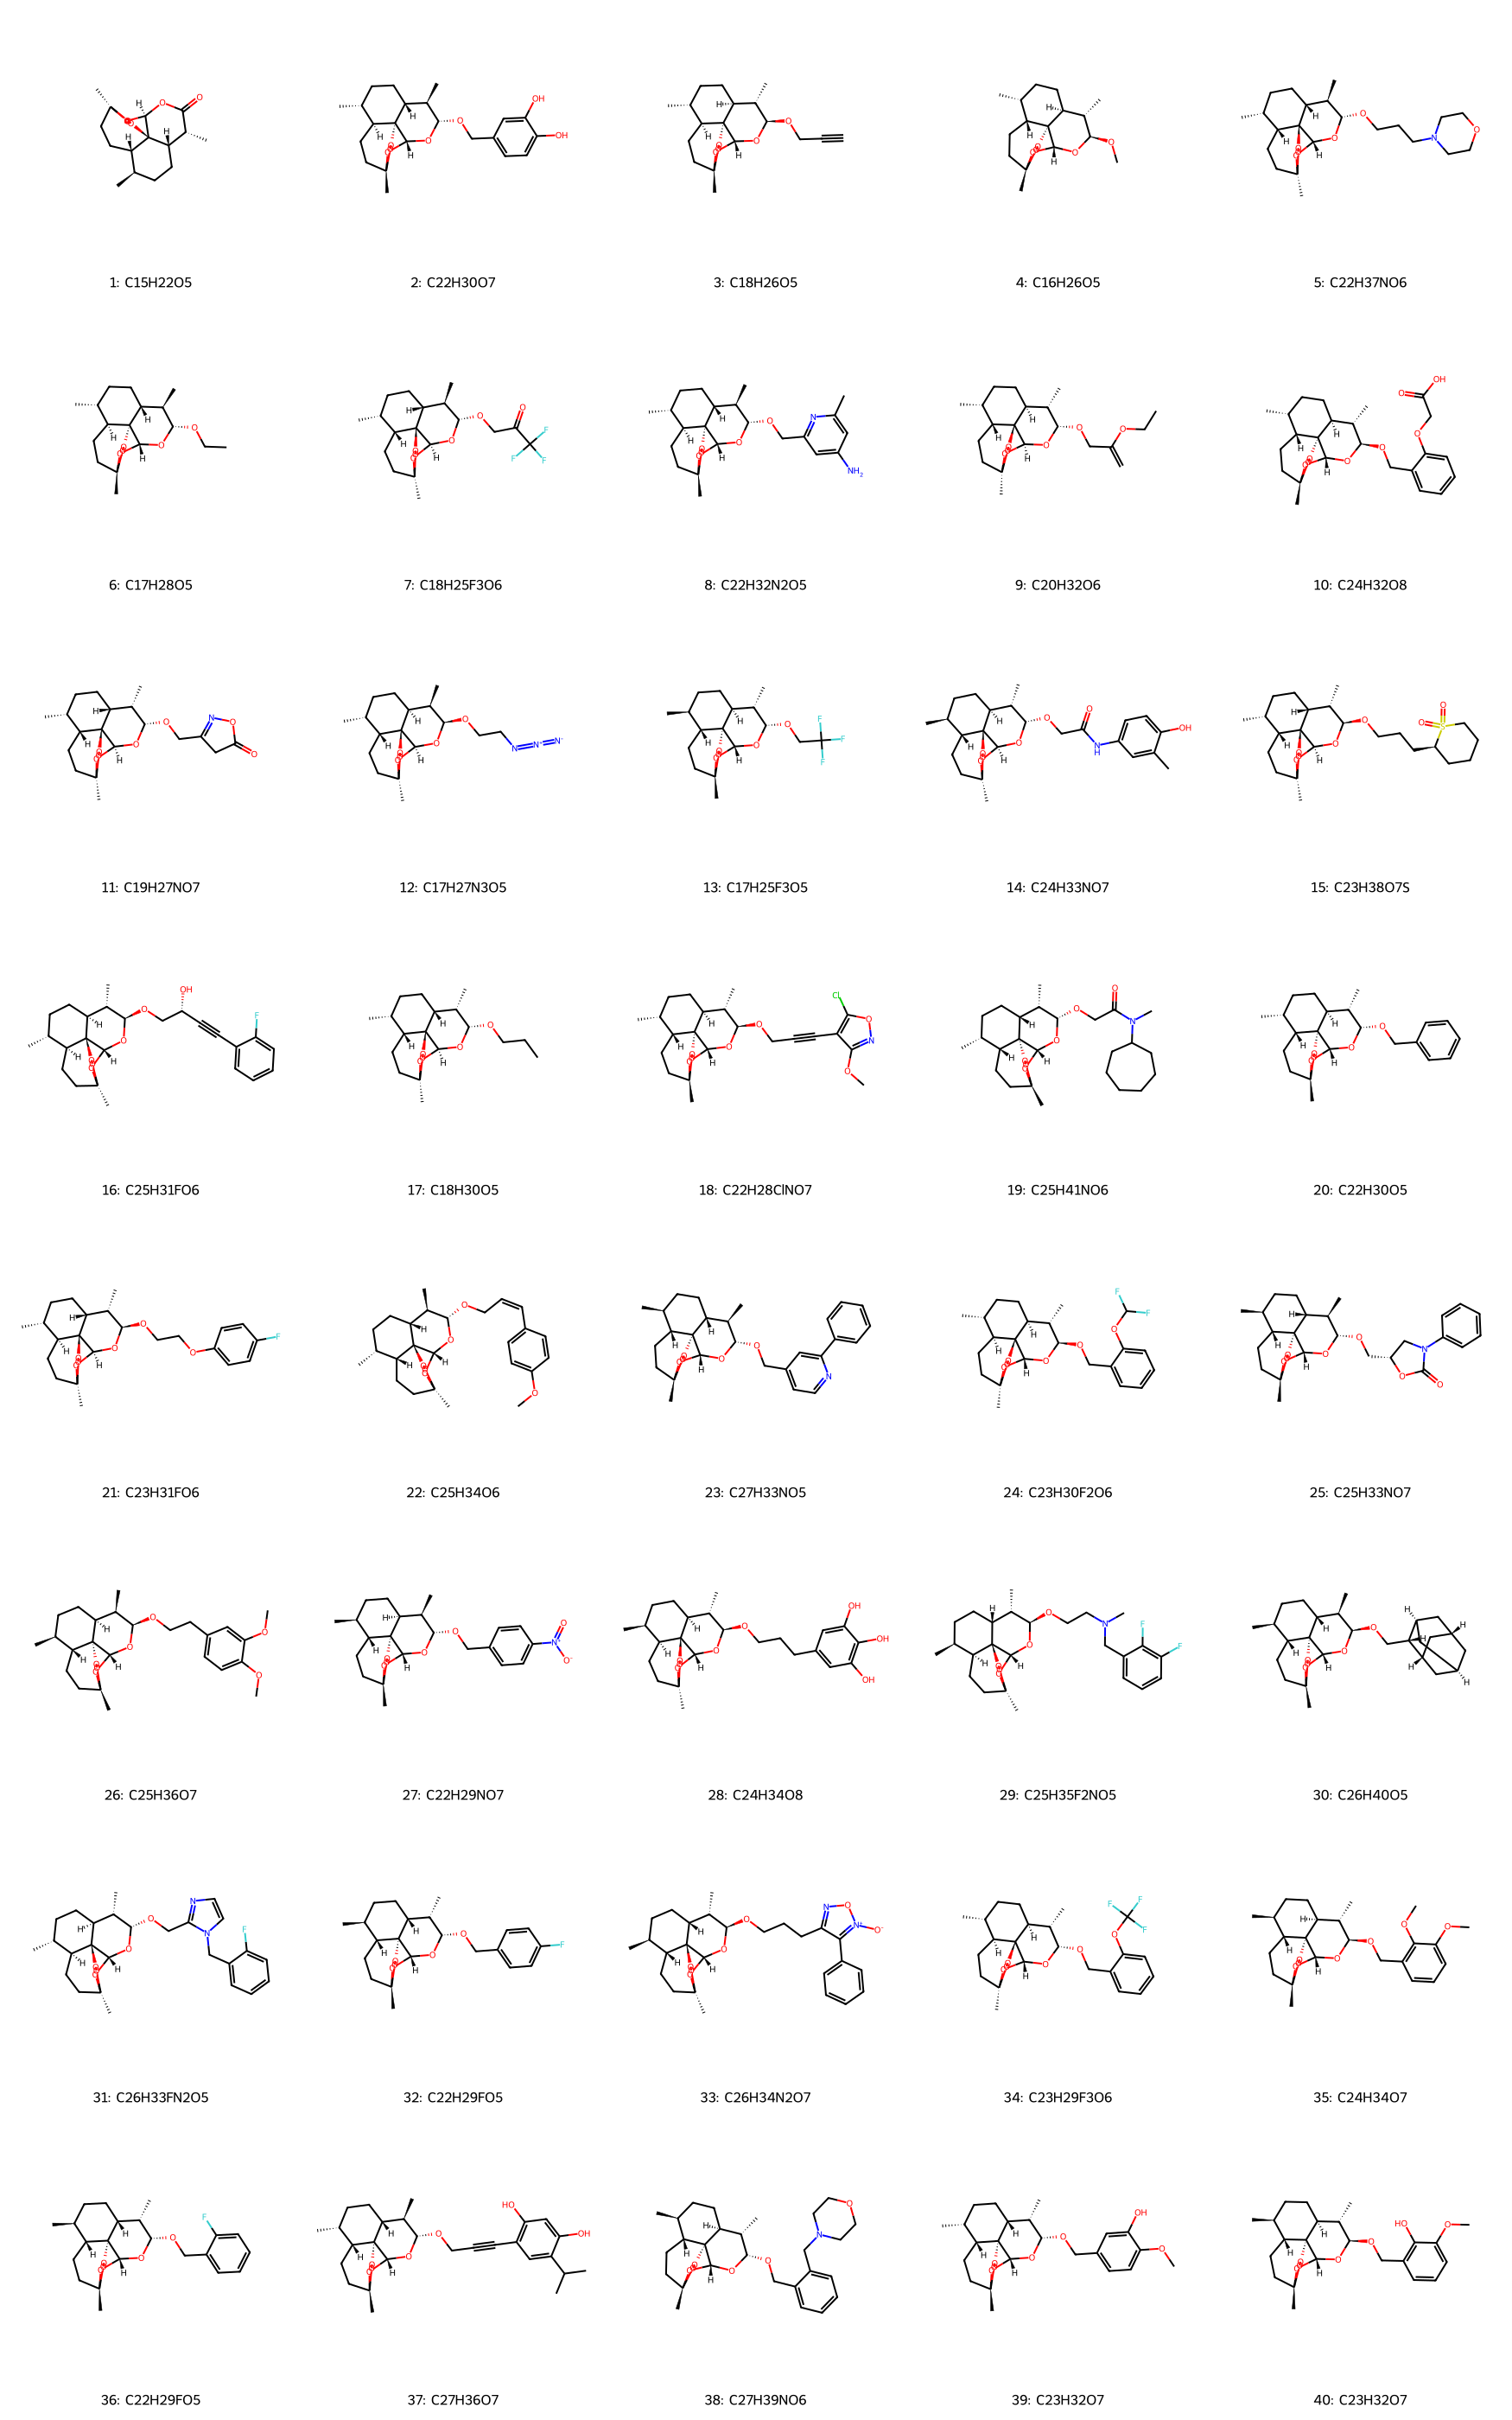

In [3]:
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import rdMolDescriptors
from rdkit.Chem import rdFMCS
import math
from IPython.display import display, Image

mols = []

for smi in df_fase1["SMILES_Quiral"]:
    mol = Chem.MolFromSmiles(smi)
    if mol is not None:
        # conservar información estereoquímica
        Chem.AssignStereochemistry(
            mol,
            cleanIt=True,
            force=True
        )
        
        mols.append(mol)

### se calcula la fórmula molecular de cada molécula
formulas = [
    rdMolDescriptors.CalcMolFormula(mol)
    for mol in mols
]

### se crean las etiquetas para cada molécula
labels = [
    f"{i+1}: {formula}"
    for i, formula in enumerate(formulas)
]

### se dibujan los derivados
img = Draw.MolsToGridImage(
    mols,
    molsPerRow=5,
    subImgSize=(350,350),
    legends=labels
)

display(img)


with open("derivados_artemisinina_completo.png", "wb") as f:
    f.write(img.data)

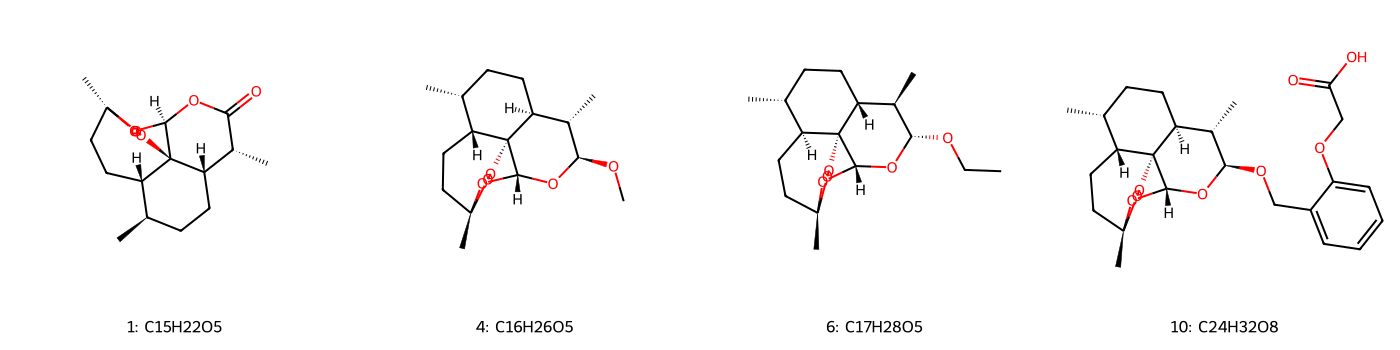

In [18]:
### imagen para 5 derivados
mols_small = [mols[0], mols[3], mols[5], mols[9]]
labels_small =[labels[0], labels[3], labels[5], labels[9]]
### se dibujan los derivados
img = Draw.MolsToGridImage(
    mols_small,
    molsPerRow=4,
    subImgSize=(350,350),
    legends=labels_small
)


display(img)


with open("derivados_artemisinina.png", "wb") as f:
    f.write(img.data)



Recordar moléculas descartadas: molecule 30, molecule 37

#### 1) Perfil fisicoquímico general de los derivados
¿Los sustituyentes introducidos modifican significativamente las propiedades asociadas a absorción, solubilidad y transporte?

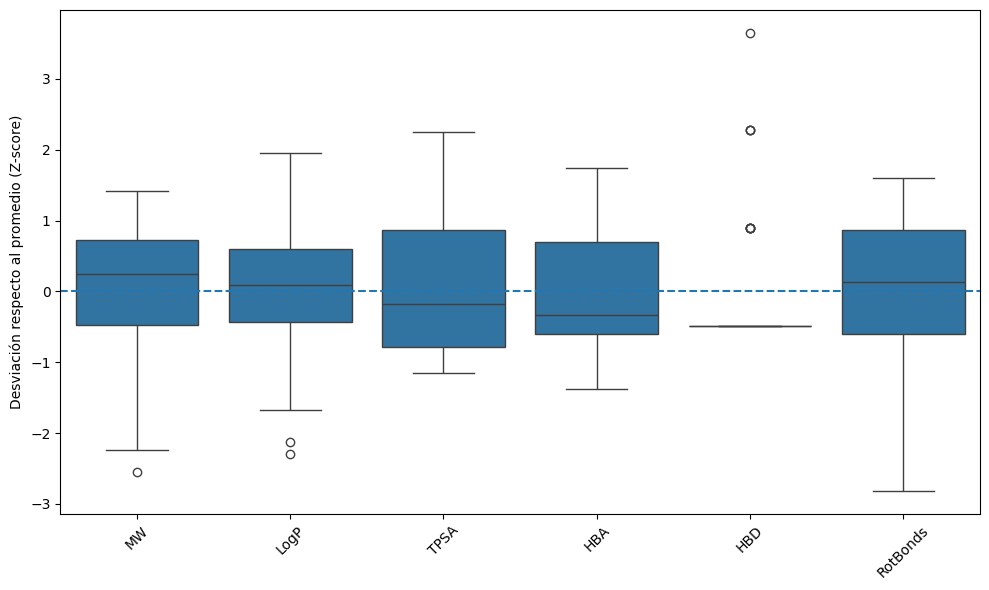

In [5]:
# Descriptores fisicoquímicos
propiedades = [
    "MW",
    "LogP",
    "TPSA",
    "HBA",
    "HBD",
    "RotBonds"
]


# Seleccionar datos
df_fisico = df_fase1[propiedades]


# Normalización Z-score
scaler = StandardScaler()

df_normalizado = scaler.fit_transform(df_fisico)


# Convertir nuevamente a dataframe
df_normalizado = pd.DataFrame(
    df_normalizado,
    columns=propiedades
)


# Pasar a formato largo
df_long = df_normalizado.melt(
    var_name="Propiedad",
    value_name="Valor normalizado"
)


# Graficar

plt.figure(figsize=(10,6))


sns.boxplot(
    data=df_long,
    x="Propiedad",
    y="Valor normalizado"
)


plt.axhline(
    0,
    linestyle="--"
)


plt.xticks(rotation=45)




plt.ylabel(
    "Desviación respecto al promedio (Z-score)"
)


plt.xlabel("")


plt.tight_layout()

plt.show()

### 2) Gap energético HOMO-LUMO
¿Los derivados se desplazan electrónicamente respecto a ART?
¿El sustituyente cambia la reactividad electrónica?

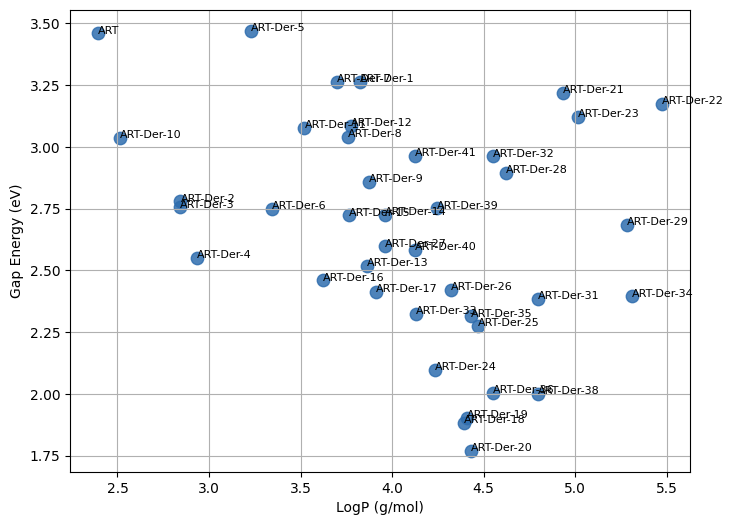

In [6]:
df_fase1["gap_ev"] = df_fase1["lumo_ev"] - df_fase1["homo_ev"]

plt.figure(figsize=(8,6))


plt.scatter(
    df_fase1["LogP"],
    df_fase1["gap_ev"],
    s=80,                 # puntos más grandes
    color="#2F6DAE",
    alpha=0.85,
)


for i in range(len(df_fase1)):
    plt.text(
        df_fase1["LogP"].iloc[i],
        df_fase1["gap_ev"].iloc[i],
        df_fase1["ID"].iloc[i],
        fontsize=8
    )


plt.xlabel(
    "LogP (g/mol)"
)

plt.ylabel(
    "Gap Energy (eV)"
)



plt.grid(True)


plt.show()

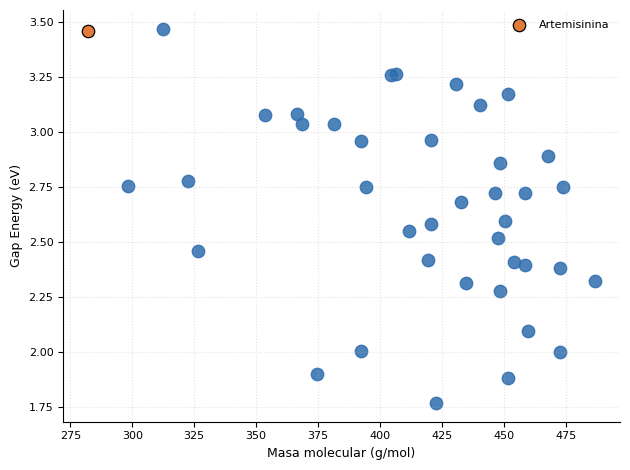

In [7]:
plt.figure()


# derivados
plt.scatter(
    df_fase1["MW"].iloc[1:],
    df_fase1["gap_ev"].iloc[1:],
    s=80,                 # puntos más grandes
    color="#2F6DAE",
    alpha=0.85,
    
)


# artemisinina
plt.scatter(
    df_fase1["MW"].iloc[0],
    df_fase1["gap_ev"].iloc[0],
    s=80,                # punto destacado más grande
    color="#E07B39",
    edgecolor="black",
    linewidth=0.9,
    label="Artemisinina",
    zorder=3
)


plt.xlabel(
    "Masa molecular (g/mol)",
    fontsize=9
)

plt.ylabel(
    "Gap Energy (eV)",
    fontsize=9
)


plt.tick_params(labelsize=8)


plt.grid(
    linestyle=":",
    alpha=0.35
)


ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


plt.legend(
    fontsize=8,
    frameon=False
)


plt.tight_layout()

plt.show()

### 3)Tamaño del sustituyente vs lipofilicidad
¿Los sustituyentes que mejoran lipofilicidad conservan propiedades electrónicas favorables?

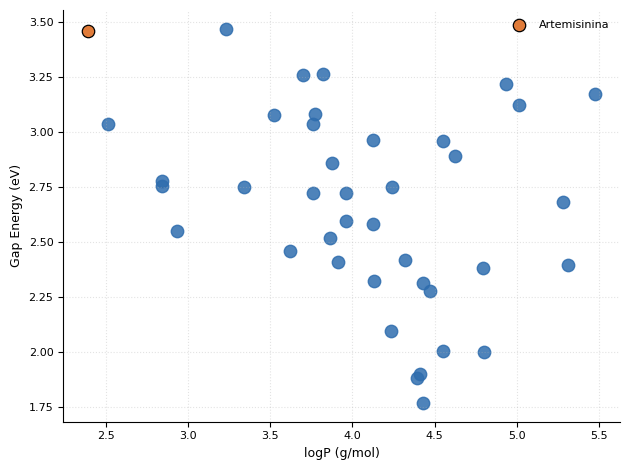

In [8]:
plt.figure()


# derivados
plt.scatter(
    df_fase1["LogP"].iloc[1:],
    df_fase1["gap_ev"].iloc[1:],
    s=80,                 # puntos más grandes
    color="#2F6DAE",
    alpha=0.85,
    
)


# artemisinina
plt.scatter(
    df_fase1["LogP"].iloc[0],
    df_fase1["gap_ev"].iloc[0],
    s=80,                # punto destacado más grande
    color="#E07B39",
    edgecolor="black",
    linewidth=0.9,
    label="Artemisinina",
    zorder=3
)


plt.xlabel(
    "logP (g/mol)",
    fontsize=9
)

plt.ylabel(
    "Gap Energy (eV)",
    fontsize=9
)


plt.tick_params(labelsize=8)


plt.grid(
    linestyle=":",
    alpha=0.35
)


ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


plt.legend(
    fontsize=8,
    frameon=False
)


plt.tight_layout()

plt.show()

### 4) Electrogfilicidad vs HOMO
¿Existe relación entre la capacidad donadora electrónica y el carácter electrofílico?
Permite discutir cómo el sustituyente altera la distribución electrónica.

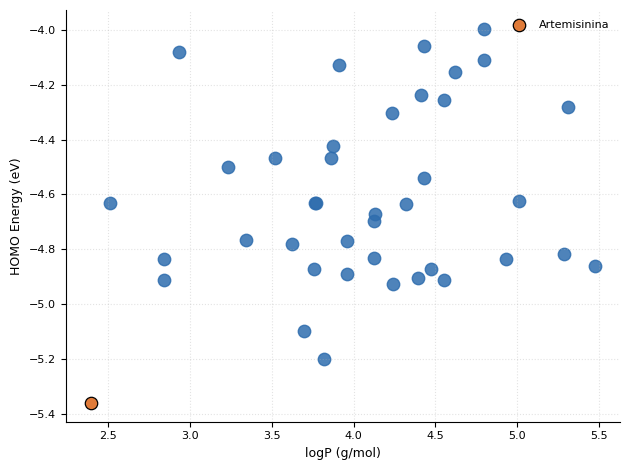

In [9]:
plt.figure()


# derivados
plt.scatter(
    df_fase1["LogP"].iloc[1:],
    df_fase1["homo_ev"].iloc[1:],
    s=80,                 # puntos más grandes
    color="#2F6DAE",
    alpha=0.85,
    
)


# artemisinina
plt.scatter(
    df_fase1["LogP"].iloc[0],
    df_fase1["homo_ev"].iloc[0],
    s=80,                # punto destacado más grande
    color="#E07B39",
    edgecolor="black",
    linewidth=0.9,
    label="Artemisinina",
    zorder=3
)


plt.xlabel(
    "logP (g/mol)",
    fontsize=9
)

plt.ylabel(
    "HOMO Energy (eV)",
    fontsize=9
)


plt.tick_params(labelsize=8)


plt.grid(
    linestyle=":",
    alpha=0.35
)


ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


plt.legend(
    fontsize=8,
    frameon=False
)


plt.tight_layout()

plt.show()

### 5) Potencial químico vs dureza química
¿Qué derivados presentan mayor tendencia a reaccionar químicamente

¿Los sustituyentes modifican la estabilidad electrónica global del sistema?

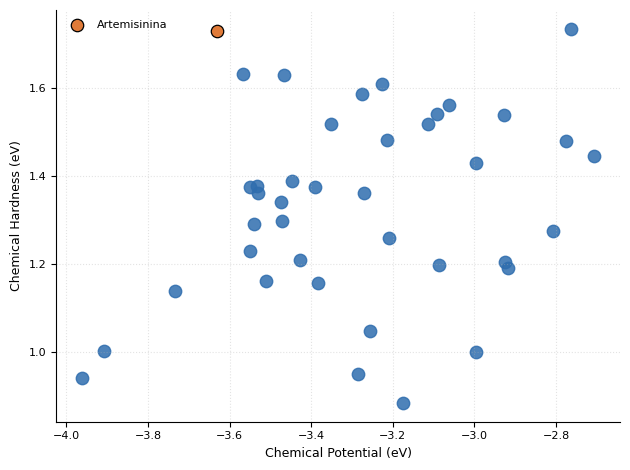

In [10]:
plt.figure()


# derivados
plt.scatter(
    df_fase1["potencial_quimico_ev"].iloc[1:],
    df_fase1["dureza_quimica_ev"].iloc[1:],
    s=80,                 # puntos más grandes
    color="#2F6DAE",
    alpha=0.85,
    
)


# artemisinina
plt.scatter(
    df_fase1["potencial_quimico_ev"].iloc[0],
    df_fase1["dureza_quimica_ev"].iloc[0],
    s=80,                # punto destacado más grande
    color="#E07B39",
    edgecolor="black",
    linewidth=0.9,
    label="Artemisinina",
    zorder=3
)


plt.xlabel(
    "Chemical Potential (eV)",
    fontsize=9
)

plt.ylabel(
    "Chemical Hardness (eV)",
    fontsize=9
)


plt.tick_params(labelsize=8)


plt.grid(
    linestyle=":",
    alpha=0.35
)


ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


plt.legend(
    fontsize=8,
    frameon=False
)


plt.tight_layout()

plt.show()

### 6) potencial quimico vs electrofilicidad


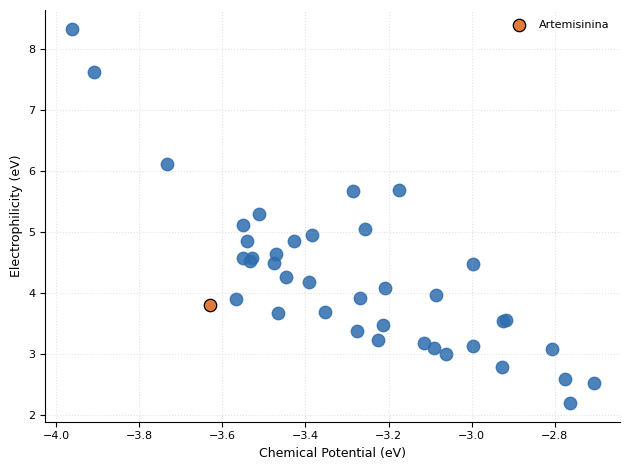

In [11]:
plt.figure()


# derivados
plt.scatter(
    df_fase1["potencial_quimico_ev"].iloc[1:],
    df_fase1["electrofilicidad_ev"].iloc[1:],
    s=80,                 # puntos más grandes
    color="#2F6DAE",
    alpha=0.85,
    
)


# artemisinina
plt.scatter(
    df_fase1["potencial_quimico_ev"].iloc[0],
    df_fase1["electrofilicidad_ev"].iloc[0],
    s=80,                # punto destacado más grande
    color="#E07B39",
    edgecolor="black",
    linewidth=0.9,
    label="Artemisinina",
    zorder=3
)


plt.xlabel(
    "Chemical Potential (eV)",
    fontsize=9
)

plt.ylabel(
    "Electrophilicity (eV)",
    fontsize=9
)


plt.tick_params(labelsize=8)


plt.grid(
    linestyle=":",
    alpha=0.35
)


ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


plt.legend(
    fontsize=8,
    frameon=False
)


plt.tight_layout()

plt.show()

In [12]:
df_fase1


,ID,SMILES_Quiral,MW,LogP,HBD,HBA,TPSA,RotBonds,energia_total_ev,homo_ev,lumo_ev,potencial_quimico_ev,dureza_quimica_ev,electrofilicidad_ev,gap_ev
0,ART,C[C@@H]1CC[C@H]2[C@H](C(=O)O[C@H]3[C@@]24[C@H]...,282.336,2.39490,0,5,53.99,0,-26136.143017,-5.359610,-1.901043,-3.630326,1.729283,3.810616,3.458566
1,ART-Der-1,C[C@H]1[C@H](OCc2ccc(O)c(O)c2)O[C@@H]2O[C@@]3(...,406.475,3.82240,2,7,86.61,3,-35944.062336,-5.199414,-1.936913,-3.568164,1.631251,3.902464,3.262501
2,ART-Der-2,C#CCO[C@H]1O[C@@H]2O[C@@]3(C)CC[C@H]4[C@H](C)C...,322.401,2.84420,0,5,46.15,2,-32755.969353,-4.835622,-2.056379,-3.446001,1.389621,4.272718,2.779243
3,ART-Der-3,CO[C@H]1O[C@@H]2O[C@@]3(C)CC[C@@H]4[C@H](C)CC[...,298.379,2.84080,0,5,46.15,1,-36406.417749,-4.910312,-2.155377,-3.532844,1.377468,4.530412,2.754935
4,ART-Der-4,C[C@H]1[C@H](OCCCN2CCOCC2)O[C@@H]2O[C@]3(C)CC[...,411.539,2.93330,0,7,58.62,5,-41226.125545,-4.080823,-1.531761,-2.806292,1.274531,3.089479,2.549062
5,ART-Der-5,CCO[C@@H]1O[C@@H]2O[C@@]3(C)CC[C@H]4[C@H](C)CC...,312.406,3.23090,0,5,46.15,2,-49613.463763,-4.499118,-1.029507,-2.764312,1.734806,2.202386,3.469611
6,ART-Der-6,C[C@H]1[C@H](OCC(=O)C(F)(F)F)O[C@H]2O[C@]3(C)C...,394.386,3.34240,0,6,63.22,3,-41407.587938,-4.765632,-2.015555,-3.390594,1.375038,4.180293,2.750076
7,ART-Der-7,Cc1cc(N)cc(CO[C@@H]2O[C@@H]3O[C@@]4(C)CC[C@H]5...,404.507,3.69682,1,7,85.06,3,-29374.617424,-5.097262,-1.835665,-3.466463,1.630799,3.684197,3.261597
8,ART-Der-8,C=C(CO[C@@H]1O[C@H]2O[C@]3(C)CC[C@@H]4[C@H](C)...,368.470,3.76120,0,6,55.38,5,-51589.533210,-4.871211,-1.832488,-3.351850,1.519362,3.697242,3.038723
9,ART-Der-9,C[C@@H]1[C@@H](OCc2ccccc2OCC(=O)O)O[C@@H]2O[C@...,448.512,3.87460,1,7,92.68,6,-40344.323899,-4.424727,-1.566808,-2.995768,1.428960,3.140265,2.857919


### 7) correlación entre descriptores

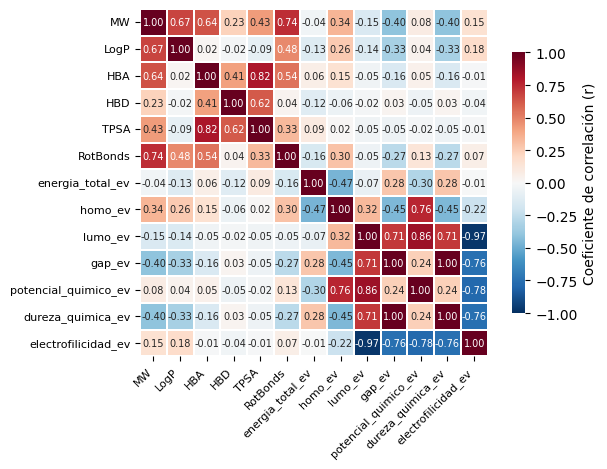

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns


# seleccionar descriptores
descriptores = df_fase1[
    [
        "MW",
        "LogP",
        "HBA",
        "HBD",
        "TPSA",
        "RotBonds",
        "energia_total_ev",
        "homo_ev",
        "lumo_ev",
        "gap_ev",
        "potencial_quimico_ev",
        "dureza_quimica_ev",
        "electrofilicidad_ev"
    ]
]


# correlación
corr = descriptores.corr()


plt.figure()


sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.3,
    annot_kws={"size":7},
    cbar_kws={
        "label":"Coeficiente de correlación (r)",
        "shrink":0.75
    }
)


plt.xticks(
    rotation=45,
    ha="right",
    fontsize=8
)

plt.yticks(
    fontsize=8
)


plt.tight_layout()

plt.show()

In [14]:
print(df_fase1.columns.tolist())

['ID', 'SMILES_Quiral', 'MW', 'LogP', 'HBD', 'HBA', 'TPSA', 'RotBonds', 'energia_total_ev', 'homo_ev', 'lumo_ev', 'potencial_quimico_ev', 'dureza_quimica_ev', 'electrofilicidad_ev', 'gap_ev']


In [15]:
df = df_fase1.rename(columns={
    'energia_total_ev': 'E_total',
    'homo_ev': 'E_HOMO',
    'lumo_ev': 'E_LUMO',
    'potencial_quimico_ev': 'μ',
    'dureza_quimica_ev': 'η',
    'electrofilicidad_ev': 'ω',
    'gap_ev': 'ΔE_FMO'
}).copy()



Pongo la gráfica más agradable a la vista

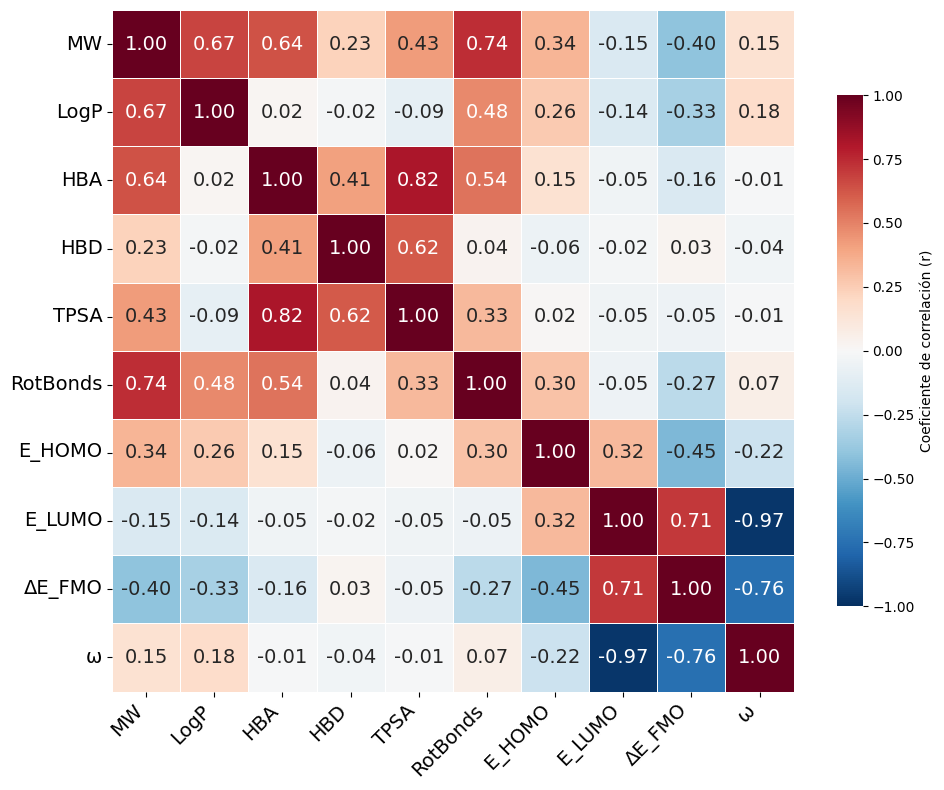

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns


# seleccionar descriptores
descriptores = df[
    [
        "MW",
        "LogP",
        "HBA",
        "HBD",
        "TPSA",
        "RotBonds",
        "E_HOMO",
        "E_LUMO",
        "ΔE_FMO",
        "ω"
    ]
]


# matriz de correlación
corr = descriptores.corr()


plt.figure(figsize=(10,8))


sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    annot_kws={"size":14},
    cbar_kws={
        "label":"Coeficiente de correlación (r)",
        "shrink":0.75
    }
)


plt.xticks(
    rotation=45,
    ha="right",
    fontsize=14
)

plt.yticks(
    fontsize=14
)


plt.tight_layout()


# guardar imagen
plt.savefig(
    "correlacion_global_pearson.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

Incluyo correlación de spearman a ver qué sale

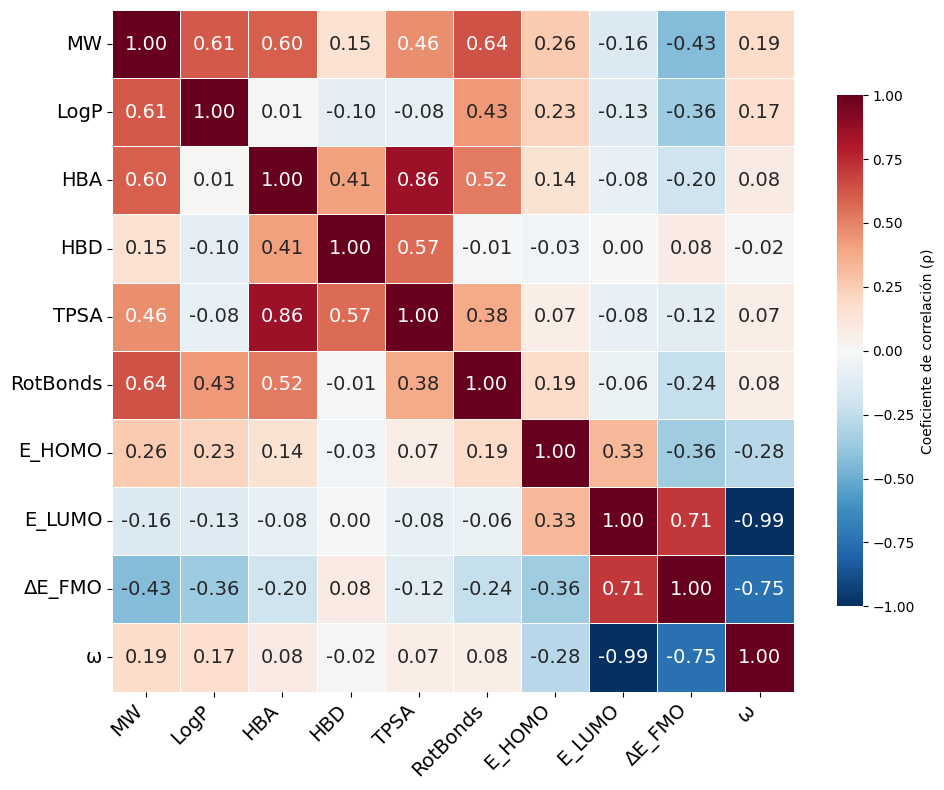

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns


# Seleccionar descriptores
descriptores = df[
    [
        "MW",
        "LogP",
        "HBA",
        "HBD",
        "TPSA",
        "RotBonds",
        "E_HOMO",
        "E_LUMO",
        "ΔE_FMO",
        "ω"
    ]
]


# Matriz de correlación de Spearman
corr_spearman = descriptores.corr(method="spearman")


# Graficar heatmap
plt.figure(figsize=(10,8))

sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    annot_kws={"size":14},
    cbar_kws={"label": "Coeficiente de correlación (ρ)","shrink":0.75}

)



plt.xticks(rotation=45, ha="right", fontsize=14)
plt.yticks(rotation=0, fontsize=14)

plt.tight_layout()

# guardar imagen
plt.savefig(
    "correlacion_global_spearman.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()